# 07 — Candidate-call segmentation

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495), Sections **3.2 and 3.3**

## 1. Objective

The detector of notebook 06 classifies *segments*. In a ten-minute pond recording the segments have to be found first. This notebook builds and tests that front end on the **labelled Mendeley recordings**, whose annotated calls give the
intervals it should find, before any pond recording is touched.

`[PAPER]` The recording is cut into consecutive **30 second** blocks. Each block is band-pass filtered with a FIR filter whose cut-offs follow the frequency range of the target species (the ranges of Table 1). The short-time energy of
**10 ms** non-overlapping frames is smoothed by a moving average of **12** values, converted to decibels, and compared with a threshold: a segment starts at the first run of **3** values above it and ends at the first run of **3** below.
The filter only serves to find the endpoints; the segment that is classified is read from the **original, unfiltered** signal.

### What the article does not specify

- the constant `C` of the threshold, which is "determined empirically";
- the order of the FIR filter;
- how the printed threshold, a maximum minus a mean, divided by `C`, is to be read as a level in decibels.

*Decision, not stated in the article:* the threshold is `mean + (max - mean) / C` of the smoothed energy in each block, so a larger `C` puts it closer to the mean and makes the front end more sensitive. The filter has 513 taps.

### What this notebook does

It measures, over the annotated calls of each species, how much of each call the candidates cover, for a grid of `C`; chooses one `C` per species with a rule fixed before the numbers; checks what the endpoint padding found necessary
for `f04` does through the frozen detector; and writes the frozen configuration that the field stage reads. No pond audio is used, and nothing here changes the detector.

### Validation, and what it cannot say

The annotations cover the **target calls** only. A candidate that overlaps none of them is not a biological false positive: it may be another frog, noise, or an unannotated call. The measures are therefore the **recall of the annotated calls**, the share of each call covered, and
the amount of candidate material relative to the annotated material (the *burden*). The share of candidate material that overlaps annotations is reported only as a diagnostic, never as a precision.

## 2. Setup

**What this section asks, and why it matters.** The notebook needs the audio of the labelled recordings, the frozen detector (for its class set, and for the end-to-end check of section 9) and the call boundaries stored by notebook 02.

In [1]:
# Every dependency, the display options, the dataset location from .env, and the detector and calls to work from.
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from dotenv import load_dotenv
from joblib import Parallel, delayed

from frog_presence import detector as D
from frog_presence import inference as I
from frog_presence import segmentation as S
from frog_presence.audio import index_wavs

sns.set_theme(style="ticks")
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 140)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
CALLS_PATH = PROCESSED_DIR / "calls.csv"
MODELS_DIR = REPO_ROOT / "models" / "gmm_robust_final"
SPLIT_PATH = PROCESSED_DIR / "final_detector_calibration" / "train_calibration_recordings.json"
RESULTS_DIR = PROCESSED_DIR / "candidate_call_segmentation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for path in (CALLS_PATH, MODELS_DIR / "final_detector_manifest.json", SPLIT_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.name}. Run notebooks 02 and 06 first.")

load_dotenv(REPO_ROOT / ".env")
mendeley_value = os.environ.get("MENDELEY_CALL_DIR")
if not mendeley_value or not Path(mendeley_value).expanduser().is_dir():
    raise RuntimeError("MENDELEY_CALL_DIR is not set to an existing folder. Copy .env.example to .env and fill in the paths.")
MENDELEY_CALL_DIR = Path(mendeley_value).expanduser()
WAVS = index_wavs(MENDELEY_CALL_DIR)

# Only folder names and relative locations are printed: absolute paths are personal to whoever runs this.
print("Dataset used :", "MENDELEY_CALL_DIR ->", MENDELEY_CALL_DIR.name)
print("Results      :", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
print("CPU workers  :", os.cpu_count())

Dataset used : MENDELEY_CALL_DIR -> mendeley
Results      : data/processed/candidate_call_segmentation
CPU workers  : 32


## 3. The frozen detector and the annotated calls

**What this section asks, and why it matters.** Segmentation is evaluated for the species the detector can represent. The calls come with their sample boundaries (stored by notebook 02), and the recordings are labelled as TRAIN or CALIBRATION
according to the detector's split, because the end-to-end check in section 9 passes candidates through models that were fitted on the TRAIN recordings.

In [2]:
# Load the frozen detector, the species' frequency bands, and the annotated calls of the usable species.
models, thresholds, manifest = D.load_detector(MODELS_DIR)
USABLE_CODES = tuple(manifest["classes"])
split = json.loads(SPLIT_PATH.read_text(encoding="utf-8"))
CALIBRATION_RECORDINGS = set(split["calibration_recordings"])

# Table 1 of the article: the frequency range of each species, at -20 dB of its maximum power.
BANDS_HZ = {"f01": (1660.0, 3100.0), "f02": (2300.0, 3390.0), "f03": (1300.0, 1530.0), "f04": (1630.0, 3900.0),
            "f05": (1680.0, 3260.0), "f06": (1000.0, 2500.0), "f07": (500.0, 2720.0), "f08": (800.0, 1700.0),
            "f10": (430.0, 3140.0)}
assert set(BANDS_HZ) == set(USABLE_CODES)

calls = pd.read_csv(CALLS_PATH)
calls["call_id"] = [f"call_{i:04d}" for i in range(len(calls))]
calls = calls[calls.code.isin(USABLE_CODES)].copy()
calls["recording"] = calls.wav.str.strip().str.lower()
calls["side"] = np.where(calls.recording.isin(CALIBRATION_RECORDINGS), "calibration", "train")
missing = sorted(set(calls.wav.str.lower()) - set(WAVS))
assert not missing, f"recordings not found: {missing[:3]}"

print("detector        :", manifest["feature"], "| Gaussians:", manifest["n_components"], "| classes:", USABLE_CODES)
inventory = (calls.groupby("code").agg(recordings=("recording", "nunique"), calls=("call_id", "size"), annotated_seconds=("seconds", "sum"),
                                       calibration_recordings=("recording", lambda r: r[calls.loc[r.index, "side"] == "calibration"].nunique()))
             .round(2))
display(inventory.join(pd.DataFrame(BANDS_HZ, index=["low_hz", "high_hz"]).T))

detector        : 20_PLP_RASTA | Gaussians: 4 | classes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')


,recordings,calls,annotated_seconds,calibration_recordings,low_hz,high_hz
code,,,,,,
f01,5,98,44.72,1,1660.0,3100.0
f02,10,99,41.72,2,2300.0,3390.0
f03,8,169,102.58,1,1300.0,1530.0
f04,9,186,77.94,3,1630.0,3900.0
f05,3,340,114.36,1,1680.0,3260.0
f06,5,54,24.94,2,1000.0,2500.0
f07,7,101,57.84,1,500.0,2720.0
f08,7,96,102.66,2,800.0,1700.0
f10,12,316,134.00,5,430.0,3140.0


`[OBSERVED]` The frozen detector holds the nine species `f01` to `f08` and `f10`, with 4 Gaussians each. The labelled recordings give each species between 3 recordings (`f05`) and 12 (`f10`) and between 54 calls (`f06`) and 340 (`f05`).
Only 1 recording of `f01`, `f03`, `f05` and `f07` is on the calibration side of the detector's split, and 5 of `f10`'s; the other recordings were used to fit the models.

`[OBSERVED]` The annotated calls of the nine species last on average between 0.34 seconds (`f05`: 114.36 seconds in 340 calls) and 1.07 seconds (`f08`: 102.66 seconds in 96 calls).

## 4. The front end on one block

**What this section asks, and why it matters.** Before the numbers, the mechanism: a block of a labelled recording, its band-passed energy in decibels, the threshold, and the intervals that result, against the annotated calls. The threshold is set from the
maximum and mean **of the block**, so a block with no calls still has a threshold, and still produces candidates.

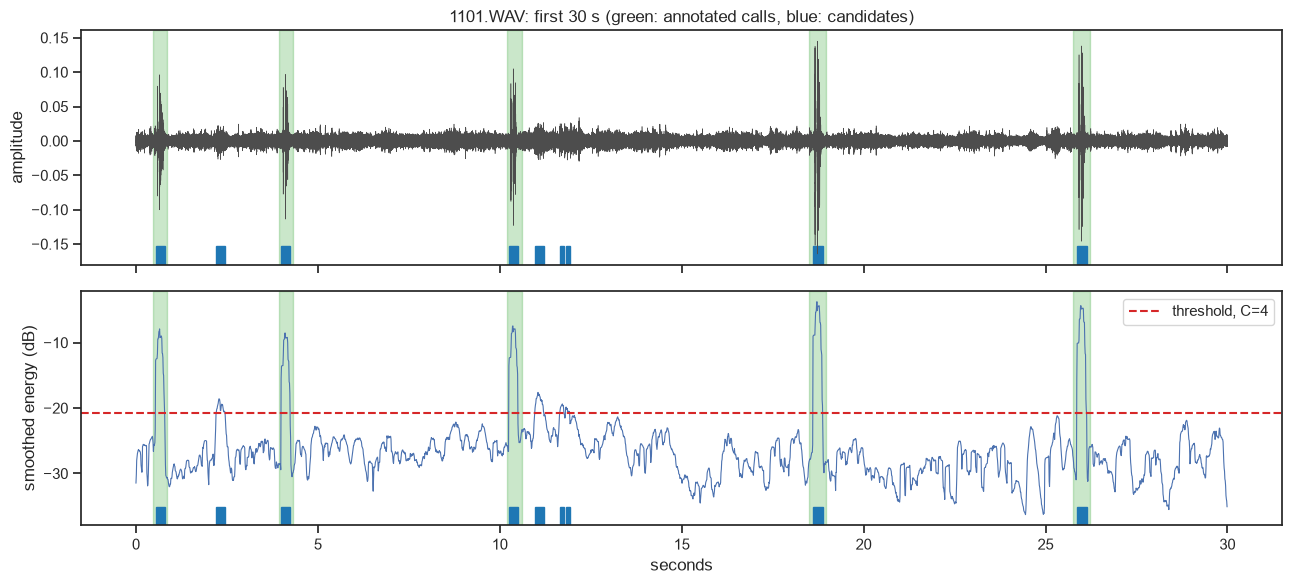

recording        : 1101.WAV (44100 Hz)
annotated calls in the block: 5 | candidates in the block: 9
threshold (dB)   : -20.83 | block maximum / mean (dB): -3.75 / -26.52


In [3]:
# Show the first 30 s block of an f01 recording: signal, smoothed band energy in dB, the threshold at C=4, and the candidates.
EXAMPLE_CODE, EXAMPLE_C = "f01", 4.0
example_wav = calls[calls.code == EXAMPLE_CODE].wav.iloc[0]
audio, sr = sf.read(WAVS[example_wav.lower()], dtype="float64")
audio = audio.mean(axis=1) if audio.ndim == 2 else audio
blocks = S.prepare_blocks(audio, sr, *BANDS_HZ[EXAMPLE_CODE])
block = blocks[0]
threshold_db = S.endpoint_threshold_db(block["ste_db"], EXAMPLE_C)
found = S.candidates_from_blocks(blocks, EXAMPLE_C)
found = found[found[:, 0] == 0]
gt = calls[(calls.code == EXAMPLE_CODE) & (calls.wav == example_wav) & (calls.start < block["end"])]

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
t = np.arange(block["start"], block["end"]) / sr
axes[0].plot(t, audio[block["start"]:block["end"]], lw=0.4, color="0.3")
axes[1].plot((block["start"] + np.arange(len(block["ste_db"])) * block["frame_samples"]) / sr, block["ste_db"], lw=0.8)
axes[1].axhline(threshold_db, color="tab:red", ls="--", label=f"threshold, C={EXAMPLE_C:g}")
for ax in axes:
    for s_, e_ in zip(gt.start, gt.end):
        ax.axvspan(s_ / sr, e_ / sr, color="tab:green", alpha=0.25)
    for _, s_, e_ in found:
        ax.axvspan(s_ / sr, e_ / sr, ymin=0, ymax=0.08, color="tab:blue")
axes[0].set(title=f"{example_wav}: first 30 s (green: annotated calls, blue: candidates)", ylabel="amplitude")
axes[1].set(xlabel="seconds", ylabel="smoothed energy (dB)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("recording        :", example_wav, f"({sr} Hz)")
print("annotated calls in the block:", len(gt), "| candidates in the block:", len(found))
print("threshold (dB)   :", round(threshold_db, 2), "| block maximum / mean (dB):", round(block["ste_db"].max(), 2), "/", round(block["ste_db"].mean(), 2))

`[OBSERVED]` In the first 30 second block of the `f01` recording `1101.WAV` there are **5 annotated calls** and **9 candidates**. The threshold is -20.83 dB, between the mean of the block (-26.52 dB) and its maximum (-3.75 dB).

`[INFERENCE]` The front end proposes more intervals than there are calls, even in a block that holds calls: it cuts a call into pieces or picks up other energy in the band. What reaches the classifier is therefore a stream of candidates, most of which are not calls.

## 5. The grid over `C`

**What this section asks, and why it matters.** The constant `C` decides how sensitive the front end is, and the article does not give it. Filtering and energy do not depend on `C`, so each recording is processed once and every value of `C` is tried on the stored energy.
The grid is the one of the earlier work (11 values from 1.25 to 10); four larger values are evaluated too, **outside** the selection, to see whether a species that falls short is limited by `C`.

*Decision, not stated in the article:* each species is segmented with **its own band** (as the article does with the ranges of Table 1) and its own `C`, and evaluated on the annotated calls of that species in each recording.

In [4]:
# Process every (species, recording) pair once, and evaluate each C on the annotated calls, in parallel.
C_GRID = (1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0)
C_CHECK = (15.0, 20.0, 30.0, 50.0)       # outside the selection grid
CALL_COVERAGE_TARGET = 0.5
TARGET_CALL_RECALL = 0.95


def process_recording(code_, wav):
    """Band energy of one recording once, and the coverage metrics for every value of C."""
    audio_, sr_ = sf.read(WAVS[wav.lower()], dtype="float64")
    audio_ = audio_.mean(axis=1) if audio_.ndim == 2 else audio_
    blocks_ = S.prepare_blocks(audio_, sr_, *BANDS_HZ[code_])
    gt_ = calls[(calls.code == code_) & (calls.wav == wav)]
    rows_ = []
    for C in (*C_GRID, *C_CHECK):
        cand = S.candidates_from_blocks(blocks_, C)
        summary, coverage = S.evaluate_candidates(gt_.start.to_numpy(), gt_.end.to_numpy(), cand, sr_, CALL_COVERAGE_TARGET)
        rows_.append({"code": code_, "wav": wav, "C": C, "in_grid": C in C_GRID, "recording_seconds": len(audio_) / sr_, **summary})
    return rows_, blocks_, sr_, len(audio_)


pairs = [(c_, w_) for (c_, w_), _ in calls.groupby(["code", "wav"])]
results = Parallel(n_jobs=-1)(delayed(process_recording)(c_, w_) for c_, w_ in pairs)
PREPARED = {pair: (blocks_, sr_, n_) for pair, (_, blocks_, sr_, n_) in zip(pairs, results)}
per_recording = pd.DataFrame([r for rows_, *_ in results for r in rows_])
per_recording["side"] = per_recording.wav.str.lower().map(lambda w: "calibration" if w in CALIBRATION_RECORDINGS else "train")

print("species-recording pairs:", len(pairs), "| audio processed:", round(per_recording.drop_duplicates(["code", "wav"]).recording_seconds.sum() / 3600, 2), "hours")
print("values of C evaluated  :", len(C_GRID) + len(C_CHECK), "|", len(per_recording), "rows")

species-recording pairs: 66 | audio processed: 4.09 hours
values of C evaluated  : 15 | 990 rows


In [5]:
# Aggregate over recordings, weighting calls by their number and durations by their length, and show the grid.
def aggregate(frame: pd.DataFrame, keys) -> pd.DataFrame:
    """Species-level metrics: recalls weighted by calls, coverage by annotated duration, overlap share by candidate duration."""
    def one(g):
        n, ann, cand = g.n_gt_calls.sum(), g.annotated_seconds_union.sum(), g.candidate_seconds.sum()
        return pd.Series({
            "recordings": len(g), "n_gt_calls": int(n), "n_candidates": int(g.n_candidates.sum()),
            "call_recall_any": (g.call_recall_any * g.n_gt_calls).sum() / n,
            "call_recall_50": (g.call_recall_50 * g.n_gt_calls).sum() / n,
            "annotation_coverage": (g.annotation_coverage * g.annotated_seconds_union).sum() / ann,
            "candidate_overlap_share": ((g.candidate_overlap_share.fillna(0) * g.candidate_seconds).sum() / cand) if cand else np.nan,
            "candidate_seconds": cand, "annotated_seconds_union": ann, "candidate_burden_ratio": cand / ann})
    return frame.groupby(keys).apply(one, include_groups=False).reset_index()


grid = aggregate(per_recording, ["code", "C"])
in_grid = grid[grid.C.isin(C_GRID)]
display(in_grid.pivot(index="C", columns="code", values="call_recall_50").round(3))
print("candidate burden (candidate seconds / annotated seconds):")
display(in_grid.pivot(index="C", columns="code", values="candidate_burden_ratio").round(2))

code,f01,f02,f03,f04,f05,f06,f07,f08,f10
C,,,,,,,,,
1.25,0.041,0.354,0.521,0.005,0.003,0.000,0.059,0.396,0.000
1.50,0.347,0.737,0.840,0.048,0.194,0.037,0.386,0.906,0.009
1.75,0.643,0.889,0.899,0.091,0.668,0.315,0.624,0.979,0.104
2.00,0.816,0.960,0.923,0.161,0.829,0.556,0.832,0.979,0.307
2.50,0.898,0.990,0.935,0.333,0.976,0.815,0.901,1.000,0.756
3.00,0.949,1.000,0.947,0.522,0.988,0.870,0.911,1.000,0.883
4.00,0.959,1.000,0.964,0.634,1.000,1.000,0.980,1.000,0.959
5.00,0.990,1.000,0.964,0.710,1.000,1.000,0.990,1.000,0.978
6.00,0.990,1.000,0.970,0.731,1.000,1.000,0.990,1.000,0.984


candidate burden (candidate seconds / annotated seconds):


code,f01,f02,f03,f04,f05,f06,f07,f08,f10
C,,,,,,,,,
1.25,0.39,0.86,0.56,0.49,0.55,0.44,0.54,0.57,0.90
1.50,0.50,1.45,0.79,0.78,0.90,0.64,1.11,1.02,1.66
1.75,0.55,2.05,0.97,1.08,1.18,0.82,1.62,1.31,2.36
2.00,0.57,2.67,1.11,1.42,1.40,1.02,2.12,1.54,2.99
2.50,0.62,3.95,1.33,1.91,1.83,1.40,2.88,1.89,4.00
3.00,0.69,5.18,1.56,2.33,2.16,1.67,3.53,2.13,4.71
4.00,1.05,7.40,1.86,3.15,2.58,2.11,4.31,2.45,5.67
5.00,1.58,9.14,2.10,3.83,2.87,2.48,4.81,2.66,6.32
6.00,2.12,10.44,2.31,4.34,3.09,2.83,5.18,2.80,6.85


`[OBSERVED]` The annotated recordings amount to **4.09 hours** of audio in 66 species-recording pairs, evaluated at 15 values of `C` (11 in the selection grid and 4 outside it).

`[OBSERVED]` Recall rises with `C` for every species, and so does the burden. At the provisional `C = 2` the front end captures at half coverage only **16.1 %** of the `f04` calls, 30.7 % of `f10` and 55.6 % of `f06`, against 96.0 % for `f02` and 97.9 % for `f08`.
At `C = 1.25` it captures almost nothing for several species (0.5 % for `f04`, 0.3 % for `f05`, 0.0 % for `f06` and `f10`).

`[OBSERVED]` The burden, the candidate material relative to the annotated material, ranges at `C = 10` from 2.78 (`f03`) to 13.56 (`f02`).

## 6. Choosing `C` for each species

**What this section asks, and why it matters.** A call that is missed here can never reach the classifier, so the rule is recall-first. A rule fixed before looking at the numbers:

1. among the values of `C` in the grid for which **at least 95 %** of the annotated calls have at least half of their duration covered, take the one with the **smallest burden**; ties go to larger annotation coverage, then fewer candidates;
2. if no value reaches 95 %, take the highest recall, then the smallest burden, then the larger coverage.

The selected values are tuned on these recordings, so they are development values and not a measure of how the front end will do on new audio.

In [6]:
# Apply the selection rule per species, compare with the provisional C=2, and summarise a single global C for reference.
def select_C(table: pd.DataFrame) -> pd.Series:
    reaches = table[table.call_recall_50 >= TARGET_CALL_RECALL]
    if len(reaches):
        row = reaches.sort_values(["candidate_burden_ratio", "annotation_coverage", "n_candidates"], ascending=[True, False, True]).iloc[0]
        reason = "smallest burden among the values reaching the recall target"
    else:
        row = table.sort_values(["call_recall_50", "candidate_burden_ratio", "annotation_coverage"], ascending=[False, True, False]).iloc[0]
        reason = "recall target not reached: highest recall"
    return pd.concat([row, pd.Series({"reason": reason})])


selected = pd.DataFrame([select_C(in_grid[in_grid.code == c_]) for c_ in USABLE_CODES]).set_index("code")
C_BY_CODE = {c_: float(selected.loc[c_, "C"]) for c_ in USABLE_CODES}
display(selected[["C", "call_recall_any", "call_recall_50", "annotation_coverage", "candidate_overlap_share", "candidate_burden_ratio", "n_candidates", "reason"]].round(3))

provisional = in_grid[in_grid.C == 2.0].set_index("code")
print("\nthe provisional C=2 for every species, against the selected value:")
display(pd.DataFrame({"selected_C": selected.C, "recall_50_selected": selected.call_recall_50, "recall_50_at_C2": provisional.call_recall_50,
                      "burden_selected": selected.candidate_burden_ratio, "burden_at_C2": provisional.candidate_burden_ratio}).round(3))

print("macro (mean over species) of one global C:")
display(in_grid.groupby("C")[["call_recall_50", "annotation_coverage", "candidate_burden_ratio"]].mean().round(3))

,C,call_recall_any,call_recall_50,annotation_coverage,candidate_overlap_share,candidate_burden_ratio,n_candidates,reason
code,,,,,,,,
f01,4.00,1.000,0.959,0.572,0.546,1.047,273.0,smallest burden among the values reaching the ...
f02,2.00,1.000,0.960,0.660,0.247,2.671,608.0,smallest burden among the values reaching the ...
f03,4.00,1.000,0.964,0.658,0.355,1.856,708.0,smallest burden among the values reaching the ...
f04,10.00,1.000,0.796,0.585,0.102,5.762,2037.0,recall target not reached: highest recall
f05,2.50,1.000,0.976,0.569,0.311,1.834,1289.0,smallest burden among the values reaching the ...
f06,4.00,1.000,1.000,0.747,0.354,2.113,200.0,smallest burden among the values reaching the ...
f07,4.00,1.000,0.980,0.864,0.200,4.314,698.0,smallest burden among the values reaching the ...
f08,1.75,1.000,0.979,0.760,0.579,1.313,494.0,smallest burden among the values reaching the ...
f10,4.00,0.997,0.959,0.595,0.105,5.665,2970.0,smallest burden among the values reaching the ...



the provisional C=2 for every species, against the selected value:


,selected_C,recall_50_selected,recall_50_at_C2,burden_selected,burden_at_C2
code,,,,,
f01,4.00,0.959,0.816,1.047,0.573
f02,2.00,0.960,0.960,2.671,2.671
f03,4.00,0.964,0.923,1.856,1.114
f04,10.00,0.796,0.161,5.762,1.420
f05,2.50,0.976,0.829,1.834,1.405
f06,4.00,1.000,0.556,2.113,1.018
f07,4.00,0.980,0.832,4.314,2.122
f08,1.75,0.979,0.979,1.313,1.541
f10,4.00,0.959,0.307,5.665,2.995


macro (mean over species) of one global C:


,call_recall_50,annotation_coverage,candidate_burden_ratio
C,,,
1.25,0.153,0.346,0.589
1.50,0.390,0.478,0.984
1.75,0.579,0.539,1.328
2.00,0.707,0.577,1.651
2.50,0.845,0.627,2.201
3.00,0.897,0.655,2.662
4.00,0.944,0.690,3.398
5.00,0.959,0.710,3.977
6.00,0.963,0.725,4.440


`[OBSERVED]` The rule selects `C` = **4 for `f01`, `f03`, `f06`, `f07` and `f10`, 2 for `f02`, 2.5 for `f05`, 1.75 for `f08` and 10 for `f04`**. Eight species reach the 95 % target (recall between 0.959 and 1.000 at half coverage). **`f04` does not**: its recall is 0.796 at `C = 10`, the highest value of the grid.

`[OBSERVED]` The selected values give a burden between **1.047** (`f01`) and **5.762** (`f04`) times the annotated material, with `f10` at 5.665 and `f07` at 4.314. Only 0.102 of the candidate material of `f04` overlaps an annotated call, and 0.105 for `f10`; the highest share is 0.579 for `f08`.

`[OBSERVED]` The provisional `C = 2` would have been unsafe for several species (recall 0.161 for `f04`, 0.307 for `f10`, 0.556 for `f06`), at a burden of 1.420, 2.995 and 1.018. A single global `C` of 4 would capture 0.944 of the calls on average with a burden of 3.398.

`[INFERENCE]` The front end is recall-first by construction, so it keeps from 1 to 6 times more audio than there are annotated calls. The annotations do not label the rest as anything, so this is not a false-positive rate, but it is the volume of material that the classifier has to reject.

## 7. Is a shortfall a problem of `C`?

**What this section asks, and why it matters.** If a species does not reach the recall target, there are two readings: the threshold is too strict, or something other than the threshold limits the endpoints. A larger `C` always lowers the threshold, so the four values
outside the grid show whether recall is still rising when sensitivity is pushed well beyond the grid.

In [7]:
# For the species that fall short at their selected C, evaluate recall and burden at the values of C outside the selection grid.
short = [c_ for c_ in USABLE_CODES if selected.loc[c_, "call_recall_50"] < TARGET_CALL_RECALL]
print("species below the recall target at their selected C:", short)
beyond = grid[grid.code.isin(short) & (grid.C >= max(C_GRID))]
display(beyond.pivot(index="C", columns="code", values="call_recall_50").round(3).rename_axis("recall at 50 % coverage"))
display(beyond.pivot(index="C", columns="code", values="candidate_burden_ratio").round(2).rename_axis("burden"))

species below the recall target at their selected C: ['f04']


code,f04
recall at 50 % coverage,
10.0,0.796
15.0,0.828
20.0,0.844
30.0,0.871
50.0,0.882


code,f04
burden,
10.0,5.76
15.0,6.87
20.0,7.50
30.0,8.17
50.0,8.77


`[OBSERVED]` `f04` is the only species below the target at its selected `C`. Beyond the grid its recall at half coverage rises slowly: **0.796 at `C = 10`, 0.828 at 15, 0.844 at 20, 0.871 at 30 and 0.882 at 50**, while the burden grows from 5.76 to 8.77.

`[INFERENCE]` Five times more sensitivity does not bring `f04` to 95 %. The shortfall is therefore not a matter of how strict the threshold is, which is consistent with calls whose endpoints are cut short, the reading tested in section 9.

## 8. Where the front end fails

**What this section asks, and why it matters.** The averages hide which calls are lost. The worst-covered calls, the spread between recordings and the calls that straddle a boundary between two 30-second blocks are shown, because the article processes the blocks separately.

In [8]:
# Per-call coverage at the selected C: the worst calls, the spread between recordings, and calls crossing a 30 s boundary.
call_rows, boundary_rows = [], []
for (code_, wav), (blocks_, sr_, n_samples) in PREPARED.items():
    cand = S.candidates_from_blocks(blocks_, C_BY_CODE[code_])
    gt_ = calls[(calls.code == code_) & (calls.wav == wav)]
    _, coverage = S.evaluate_candidates(gt_.start.to_numpy(), gt_.end.to_numpy(), cand, sr_, CALL_COVERAGE_TARGET)
    block_len = int(round(S.BLOCK_SECONDS * sr_))
    for row, cov in zip(gt_.itertuples(), coverage):
        call_rows.append({"call_id": row.call_id, "code": code_, "wav": wav, "side": row.side, "coverage": cov,
                          "crosses_block_boundary": row.start // block_len != (row.end - 1) // block_len})
call_coverage = pd.DataFrame(call_rows)

print("worst-covered annotated calls:")
display(call_coverage.sort_values("coverage").head(8).round(3))
by_recording = per_recording[per_recording.apply(lambda r: r.C == C_BY_CODE[r.code], axis=1)]
spread = by_recording.groupby("code").call_recall_50.agg(["min", "median", "max"])
spread["recordings"] = by_recording.groupby("code").size()
print("recall at 50 % coverage by recording, at the selected C:")
display(spread.round(3))
crossing = call_coverage[call_coverage.crosses_block_boundary]
print("annotated calls crossing a 30 s boundary:", len(crossing), "of", len(call_coverage),
      "| captured at 50 % coverage:", int((crossing.coverage >= CALL_COVERAGE_TARGET).sum()),
      "| of the others:", f"{(call_coverage[~call_coverage.crosses_block_boundary].coverage >= CALL_COVERAGE_TARGET).mean():.3f}")

worst-covered annotated calls:


,call_id,code,wav,side,coverage,crosses_block_boundary
1359,call_1301,f10,Epetersi_Daniel1.WAV,train,0.000,False
1113,call_1113,f08,LS100169 R. margaritifer sc28485 Limoncocha.WAV,train,0.133,False
1360,call_1302,f10,Epetersi_Daniel1.WAV,train,0.182,False
1361,call_1303,f10,Epetersi_Daniel1.WAV,train,0.190,False
962,call_0962,f07,"D.triangulum, H.geographicus, H.lanciformis.WAV",train,0.295,False
1114,call_1114,f08,LS100169 R. margaritifer sc28485 Limoncocha.WAV,train,0.297,False
202,call_0202,f03,Hcinerascens.WAV,calibration,0.368,False
253,call_0253,f03,LS100305_Daniel1.WAV,train,0.368,False


recall at 50 % coverage by recording, at the selected C:


,min,median,max,recordings
code,,,,
f01,0.842,1.000,1.0,5
f02,0.750,1.000,1.0,10
f03,0.885,1.000,1.0,8
f04,0.455,0.955,1.0,9
f05,0.970,0.978,1.0,3
f06,1.000,1.000,1.0,5
f07,0.938,1.000,1.0,7
f08,0.889,1.000,1.0,7
f10,0.688,0.970,1.0,12


annotated calls crossing a 30 s boundary: 21 of 1459 | captured at 50 % coverage: 17 | of the others: 0.949


`[OBSERVED]` The worst-covered calls are concentrated in a few recordings: three `f10` calls of `Epetersi_Daniel1.WAV` (coverage 0.000, 0.182 and 0.190) and two `f08` calls of one recording (0.133 and 0.297). By recording, the recall of `f04` at half coverage ranges from **0.455 to 1.000**
(median 0.955), that of `f10` from 0.688 and that of `f02` from 0.750.

`[OBSERVED]` Of the **21 annotated calls that cross a 30-second boundary**, 17 are captured at half coverage (0.810), against 0.949 of the other calls.

`[INFERENCE]` The shortfalls belong to individual recordings more than to species, which suggests that the signal-to-noise ratio of the recording, and not the species, is what the threshold rule is sensitive to. Block boundaries cost some calls, because each block is segmented on its own.

## 9. Endpoint padding

**What this section asks, and why it matters.** A species whose calls are only partly covered, with a recall that more sensitivity does not raise, points at the **endpoints**: the candidates may be slightly too short on each side. The article does not describe a correction. This section widens every
candidate of the species by a small symmetric padding, clipped to the recording and merged when candidates then overlap, and measures coverage. Nothing else changes.

*This is a project extension, not part of the article.* Padding is tested first on the coverage of the annotated calls, for every species at its selected `C`.

In [9]:
# Widen the candidates of every species by 0 to 200 ms per side and measure the coverage of its annotated calls.
PADDINGS_MS = (0, 10, 20, 30, 50, 75, 100, 150, 200)
pad_rows = []
for (code_, wav), (blocks_, sr_, n_samples) in PREPARED.items():
    cand = S.candidates_from_blocks(blocks_, C_BY_CODE[code_])
    gt_ = calls[(calls.code == code_) & (calls.wav == wav)]
    for ms in PADDINGS_MS:
        padded = S.pad_intervals(cand[:, 1:], int(round(sr_ * ms / 1000.0)), n_samples)
        summary, _ = S.evaluate_candidates(gt_.start.to_numpy(), gt_.end.to_numpy(), padded, sr_, CALL_COVERAGE_TARGET)
        summary["n_candidates"] = int(len(padded))
        pad_rows.append({"code": code_, "wav": wav, "padding_ms": ms, **summary})
padding = aggregate(pd.DataFrame(pad_rows), ["code", "padding_ms"])

display(padding.pivot(index="padding_ms", columns="code", values="call_recall_50").round(3).rename_axis("recall at 50 % coverage"))
display(padding.pivot(index="padding_ms", columns="code", values="candidate_burden_ratio").round(2).rename_axis("burden"))

code,f01,f02,f03,f04,f05,f06,f07,f08,f10
recall at 50 % coverage,,,,,,,,,
0,0.959,0.96,0.964,0.796,0.976,1.0,0.98,0.979,0.959
10,1.000,1.00,0.970,0.957,1.000,1.0,0.99,0.979,0.991
20,1.000,1.00,0.976,1.000,1.000,1.0,0.99,0.979,0.991
30,1.000,1.00,1.000,1.000,1.000,1.0,0.99,0.979,0.991
50,1.000,1.00,1.000,1.000,1.000,1.0,1.00,0.990,0.991
75,1.000,1.00,1.000,1.000,1.000,1.0,1.00,1.000,0.997
100,1.000,1.00,1.000,1.000,1.000,1.0,1.00,1.000,0.997
150,1.000,1.00,1.000,1.000,1.000,1.0,1.00,1.000,0.997
200,1.000,1.00,1.000,1.000,1.000,1.0,1.00,1.000,0.997


code,f01,f02,f03,f04,f05,f06,f07,f08,f10
burden,,,,,,,,,
0,1.05,2.67,1.86,5.76,1.83,2.11,4.31,1.31,5.67
10,1.17,2.96,1.99,6.28,2.06,2.27,4.55,1.41,6.11
20,1.29,3.25,2.13,6.80,2.28,2.43,4.79,1.50,6.54
30,1.41,3.52,2.25,7.28,2.50,2.58,5.00,1.59,6.94
50,1.65,4.05,2.48,8.17,2.94,2.86,5.38,1.75,7.65
75,1.94,4.69,2.75,9.17,3.47,3.19,5.78,1.95,8.43
100,2.23,5.30,3.00,10.07,3.98,3.49,6.14,2.13,9.15
150,2.80,6.47,3.44,11.60,4.95,4.04,6.77,2.47,10.46
200,3.34,7.58,3.82,12.88,5.77,4.52,7.33,2.78,11.63


`[OBSERVED]` Widening the candidates raises the coverage of `f04` from 0.796 to **0.957 at 10 ms and 1.000 at 20 ms** per side. Every other species is at or above 0.959 without padding, and padding changes them little: `f10` goes from 0.959 to 0.991 at 10 ms, `f03` from 0.964 to 0.976 at 20 ms.

`[OBSERVED]` The cost in burden is modest for small paddings: for `f04` 5.76 without padding, 6.28 at 10 ms and 6.80 at 20 ms, against 12.88 at 200 ms.

## 10. Padding through the frozen detector

**What this section asks, and why it matters.** The detector never sees a covered/not-covered flag; it sees the waveform of the candidate. More context can restore the structure of a call, or add noise and merge neighbouring events. So the species that need padding
are passed through the **frozen** detector at a few paddings, and the end-to-end recovery of their annotated calls is measured: a call is *recovered* when a candidate that covers at least half of it is accepted as that species.

The check is made on all recordings and, separately, on the **calibration recordings**, which the models did not train on.

In [10]:
# Pass the candidates of the species that fall short through the frozen detector at paddings 0, 10 and 20 ms.
END_TO_END_PADDINGS = (0, 10, 20)
codes_list = list(models)


def end_to_end(code_, wav):
    """Detector decisions for the candidates of one species in one recording, at each padding, against its annotated calls."""
    blocks_, sr_, n_samples = PREPARED[(code_, wav)]
    audio_, _ = sf.read(WAVS[wav.lower()], dtype="float64")
    audio_ = audio_.mean(axis=1) if audio_.ndim == 2 else audio_
    cand = S.candidates_from_blocks(blocks_, C_BY_CODE[code_])
    gt_ = calls[(calls.code == code_) & (calls.wav == wav)]
    gs, ge = gt_.start.to_numpy(), gt_.end.to_numpy()
    glen = np.maximum(1, ge - gs)
    candidate_rows, call_rows_ = [], []
    for ms in END_TO_END_PADDINGS:
        iv = S.pad_intervals(cand[:, 1:], int(round(sr_ * ms / 1000.0)), n_samples)
        out = I.detect(models, thresholds, I.candidate_features(audio_, sr_, iv))
        accepted_here = out["accepted"] & (out["hypothesis"] == codes_list.index(code_))
        overlap = np.clip(np.minimum(iv[:, 1][:, None], ge[None, :]) - np.maximum(iv[:, 0][:, None], gs[None, :]), 0, None)
        share = overlap / glen[None, :]
        _, union_cov = S.evaluate_candidates(gs, ge, iv, sr_, CALL_COVERAGE_TARGET)
        for j, cid in enumerate(gt_.call_id):
            call_rows_.append({"code": code_, "wav": wav, "padding_ms": ms, "call_id": cid, "side": gt_.side.iloc[j],
                               "segmentation_50": bool(union_cov[j] >= CALL_COVERAGE_TARGET),
                               "accepted_any_overlap": bool((accepted_here & (overlap[:, j] > 0)).any()),
                               "end_to_end_50": bool((accepted_here & (share[:, j] >= CALL_COVERAGE_TARGET)).any())})
        candidate_rows.append({"code": code_, "wav": wav, "padding_ms": ms, "side": gt_.side.iloc[0], "n_candidates": len(iv),
                               "n_valid": int(out["valid"].sum()), "accepted_as_species": int(accepted_here.sum()),
                               "accepted_overlapping_annotation": int((accepted_here & (overlap.sum(axis=1) > 0)).sum())})
    return pd.DataFrame(call_rows_), pd.DataFrame(candidate_rows)


tested = short
jobs = [(c_, w_) for (c_, w_) in PREPARED if c_ in tested]
outcome = Parallel(n_jobs=-1)(delayed(end_to_end)(c_, w_) for c_, w_ in jobs)
e2e_calls = pd.concat([o[0] for o in outcome], ignore_index=True)
e2e_candidates = pd.concat([o[1] for o in outcome], ignore_index=True)

def summarise_e2e(subset_calls, subset_cands):
    calls_by = subset_calls.groupby(["code", "padding_ms"]).agg(calls=("call_id", "size"), segmentation_50=("segmentation_50", "mean"),
                                                              accepted_any_overlap=("accepted_any_overlap", "mean"), end_to_end_50=("end_to_end_50", "mean"))
    cands_by = subset_cands.groupby(["code", "padding_ms"]).agg(candidates=("n_candidates", "sum"), accepted_as_species=("accepted_as_species", "sum"),
                                                              accepted_overlapping_annotation=("accepted_overlapping_annotation", "sum"))
    return calls_by.join(cands_by)


print("species tested:", tested)
print("all recordings:")
display(summarise_e2e(e2e_calls, e2e_candidates).round(4))
print("calibration recordings only (not seen by the models in training):")
display(summarise_e2e(e2e_calls[e2e_calls.side == "calibration"], e2e_candidates[e2e_candidates.side == "calibration"]).round(4))

species tested: ['f04']
all recordings:


calls  segmentation_50  accepted_any_overlap  end_to_end_50  candidates  accepted_as_species  accepted_overlapping_annotation
code padding_ms                                                                                                                               
f04  0             186           0.7957                0.9301         0.7043        2034                 1033                              178
     10            186           0.9570                0.9355         0.8763        2033                 1003                              179
     20            186           1.0000                0.9301         0.9247        1907                  886                              175

calibration recordings only (not seen by the models in training):


calls  segmentation_50  accepted_any_overlap  end_to_end_50  candidates  accepted_as_species  accepted_overlapping_annotation
code padding_ms                                                                                                                               
f04  0              47              1.0                0.9149         0.9149         471                  205                               43
     10             47              1.0                0.9362         0.9362         471                  199                               44
     20             47              1.0                0.9149         0.9149         441                  179                               43

`[OBSERVED]` Through the frozen detector, `f04` calls are recovered end to end (a candidate covering at least half of the call is accepted as `f04`) in **0.7043, 0.8763 and 0.9247** of the calls at 0, 10 and 20 ms, on all 9 recordings. The number of candidates accepted as `f04` falls from 1033 to 886, and of those only 178, 179 and 175
overlap an annotated `f04` call.

`[OBSERVED]` On the **3 calibration recordings** (47 calls), which the models did not train on, segmentation already covers **all** the calls at 0 ms, and the end-to-end recovery is 0.9149, 0.9362 and 0.9149 at 0, 10 and 20 ms: **padding gives no benefit there**.

`[INFERENCE]` The gain from padding comes from the recordings that the models were trained on, and within them from the few recordings in which the endpoints are cut short (section 8). It is not shown to generalise to unseen recordings. The recovered calls also depend on the detector accepting them, so a few calls are lost in identification
or verification whatever the padding (8.5 % of the 47 calibration calls, from the 0.9149 recovered with full segmentation coverage).

## 11. Padding rule and the frozen configuration

**What this section asks, and why it matters.** A rule fixed before the numbers: for a species that falls short, take the padding (among 0, 10 and 20 ms) with the highest end-to-end recovery on **all** recordings; ties go to the higher
accepted-with-any-overlap recall, then to the **smaller** padding. Species that reach the recall target without padding get none. The result is written as the configuration the field stage reads.

In [11]:
# Apply the padding rule, build the frozen configuration, compare it with the one on disk, and write it.
PADDING_BY_CODE = {c_: 0 for c_ in USABLE_CODES}
overall = summarise_e2e(e2e_calls, e2e_candidates).reset_index()
for c_ in tested:
    sub = overall[overall.code == c_].sort_values(["end_to_end_50", "accepted_any_overlap", "padding_ms"], ascending=[False, False, True])
    PADDING_BY_CODE[c_] = int(sub.iloc[0].padding_ms)
display(pd.DataFrame({"C": C_BY_CODE, "padding_ms_per_side": PADDING_BY_CODE, "band_low_hz": {c: BANDS_HZ[c][0] for c in USABLE_CODES},
                      "band_high_hz": {c: BANDS_HZ[c][1] for c in USABLE_CODES}}))

configuration = {
    "source_notebook": "07_candidate_segmentation",
    "scope": "labelled Mendeley recordings; no pond audio",
    "field_audio_used": False,
    "paper_frontend": {"block_seconds": S.BLOCK_SECONDS, "ste_frame_seconds": S.STE_FRAME_SECONDS, "ste_overlap": 0.0,
                       "moving_average_length": S.STE_MA_LENGTH, "endpoint_run_length": S.ENDPOINT_RUN,
                       "species_frequency_bands_hz": {c: list(b) for c, b in BANDS_HZ.items()}},
    "replication_decisions": {"fir_numtaps": S.FIR_NUMTAPS, "filter_alignment": "fftconvolve, mode=same",
                              "moving_average_boundary_mode": "numpy convolve, mode=same",
                              "threshold_interpretation": "mean(STE_dB) + (max(STE_dB) - mean(STE_dB)) / C, per 30 s block",
                              "paper_C_reported": False},
    "selection": {"call_coverage_target": CALL_COVERAGE_TARGET, "target_call_recall": TARGET_CALL_RECALL,
                  "C_grid": list(C_GRID), "C_by_code": C_BY_CODE, "padding_ms_by_code": PADDING_BY_CODE,
                  "padding_rule": "highest end-to-end recovery among 0, 10 and 20 ms for species below the recall target; smaller padding on ties"},
    "limitations": [
        "C and padding are tuned on the labelled recordings and are not field-performance estimates",
        "annotations cover target calls only, so candidates outside them are not biological false positives",
        "padding is a project extension that the article does not describe",
    ],
}
CONFIG_PATH = RESULTS_DIR / "final_segmentation_configuration.json"
if CONFIG_PATH.exists():
    on_disk = json.loads(CONFIG_PATH.read_text(encoding="utf-8")).get("selection", {})
    print("C values identical to the configuration on disk:", on_disk.get("C_by_code") == C_BY_CODE)
CONFIG_PATH.write_text(json.dumps(configuration, indent=2), encoding="utf-8")
print("reloads identically:", json.loads(CONFIG_PATH.read_text(encoding="utf-8")) == configuration)

,C,padding_ms_per_side,band_low_hz,band_high_hz
f01,4.00,0,1660.0,3100.0
f02,2.00,0,2300.0,3390.0
f03,4.00,0,1300.0,1530.0
f04,10.00,20,1630.0,3900.0
f05,2.50,0,1680.0,3260.0
f06,4.00,0,1000.0,2500.0
f07,4.00,0,500.0,2720.0
f08,1.75,0,800.0,1700.0
f10,4.00,0,430.0,3140.0


C values identical to the configuration on disk: True
reloads identically: True


`[OBSERVED]` The padding rule selects **20 ms for `f04`** (the highest end-to-end recovery, 0.9247) and none for the other species. The `C` values are **identical to the configuration already on disk**, and the new file reloads identically.

`[INFERENCE]` The 20 ms padding for `f04` is kept because the rule fixed in advance selects it, but its support is weak: it rests on recordings used to train the models and does not change the result on unseen ones. It is a project extension that the article does not describe, and a candidate for the sensitivity analysis of the field stage.

## 12. Candidate durations

**What this section asks, and why it matters.** The article relates the moving average of 12 values to the shortest call that will be segmented, but nothing stops a candidate from being much shorter than a call. Very short candidates have few frames, so their mean score is noisy, and the field recordings contain far more candidates than calls.
The durations of the candidates at the frozen configuration are summarised, with the share of them that overlap an annotated call.

In [12]:
# Durations of the candidates at the frozen configuration, and how often candidates of each length overlap an annotated call.
duration_rows = []
for (code_, wav), (blocks_, sr_, n_samples) in PREPARED.items():
    cand = S.candidates_from_blocks(blocks_, C_BY_CODE[code_])
    iv = S.pad_intervals(cand[:, 1:], int(round(sr_ * PADDING_BY_CODE[code_] / 1000.0)), n_samples)
    gt_ = calls[(calls.code == code_) & (calls.wav == wav)]
    gs, ge = gt_.start.to_numpy(), gt_.end.to_numpy()
    overlaps = (np.minimum(iv[:, 1][:, None], ge[None, :]) > np.maximum(iv[:, 0][:, None], gs[None, :])).any(axis=1)
    duration_rows.append(pd.DataFrame({"code": code_, "duration_s": (iv[:, 1] - iv[:, 0]) / sr_, "overlaps_annotation": overlaps}))
durations = pd.concat(duration_rows, ignore_index=True)
durations["duration_bin_s"] = pd.cut(durations.duration_s, [0, 0.05, 0.1, 0.2, 0.5, 1, 5, np.inf], right=False)
display(durations.groupby("duration_bin_s", observed=True).agg(candidates=("code", "size"), share=("code", lambda s: len(s) / len(durations)),
                                                           overlapping_an_annotated_call=("overlaps_annotation", "mean")).round(3))
print("median candidate duration (s):", round(durations.duration_s.median(), 3), "| candidates:", len(durations))

,candidates,share,overlapping_an_annotated_call
duration_bin_s,,,
"[0.0, 0.05)",163,0.018,0.012
"[0.05, 0.1)",713,0.078,0.007
"[0.1, 0.2)",4140,0.454,0.088
"[0.2, 0.5)",3429,0.376,0.297
"[0.5, 1.0)",576,0.063,0.274
"[1.0, 5.0)",98,0.011,0.214
"[5.0, inf)",9,0.001,0.556


median candidate duration (s): 0.18 | candidates: 9128


`[OBSERVED]` The 9128 candidates at the frozen configuration have a median duration of **0.18 seconds**, and **55.0 %** are shorter than 0.2 seconds. Those shorter than 0.1 seconds are 9.6 % of the candidates and overlap an annotated call in 1.2 % (below 0.05 s) and 0.7 % (0.05 to 0.1 s) of the cases. Candidates between 0.2 and 0.5 seconds overlap a call in 29.7 %.

`[INFERENCE]` The annotated calls average 0.34 seconds or more, so candidates of a few hundredths of a second are almost never calls. They have very few analysis frames, so their mean score is noisy. The article relates the moving average of 12 values to the shortest call that is segmented, but nothing in the rule enforces a minimum duration. Whether
such candidates matter for the field results is examined in the field stage.

## 13. Save the tables

**What this section asks, and why it matters.** The tables behind the numbers are written so that they can be inspected without reprocessing the audio.

In [13]:
# Write the grid, selection, padding and per-call tables, and list only the files this notebook wrote.
OUTPUTS = {
    "grid_by_recording.csv": per_recording, "grid_by_species.csv": grid, "selected_C_by_species.csv": selected.reset_index(),
    "call_coverage_at_selected_C.csv": call_coverage, "padding_by_species.csv": padding,
    "end_to_end_calls.csv": e2e_calls, "end_to_end_candidates.csv": e2e_candidates,
}
for name, table in OUTPUTS.items():
    table.to_csv(RESULTS_DIR / name, index=False)
print("written to", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
for name in ["final_segmentation_configuration.json", *OUTPUTS]:
    print(f"  {name:<40} {(RESULTS_DIR / name).stat().st_size / 1e6:>7.3f} MB")

written to data/processed/candidate_call_segmentation
  final_segmentation_configuration.json      0.002 MB
  grid_by_recording.csv                      0.167 MB
  grid_by_species.csv                        0.016 MB
  selected_C_by_species.csv                  0.002 MB
  call_coverage_at_selected_C.csv            0.108 MB
  padding_by_species.csv                     0.009 MB
  end_to_end_calls.csv                       0.040 MB
  end_to_end_candidates.csv                  0.002 MB


## 14. Conclusions and limitations

**What this notebook delivers.** The front end of Sections 3.2 and 3.3, measured against the annotated calls of the labelled recordings: the coverage of each species' calls at each value of `C`, one `C` per species chosen with a rule fixed beforehand, a check of the endpoint padding through the frozen detector, and the frozen configuration
that the field stage reads, in `data/processed/candidate_call_segmentation/final_segmentation_configuration.json`. The code is in `frog_presence.segmentation` with tests, and reproduces the earlier work exactly (the 726 recording-by-`C` metrics of the previous grid, and the same selected values), in seconds instead of
minutes.

**What was found.**

1. **`C` has to be tuned per species.** The provisional `C = 2` would capture 16.1 % of the `f04` calls and 30.7 % of `f10`; the selected values capture at least 95.9 % for eight species.
2. **`f04` is the exception**: 0.796 at the highest `C` of the grid, and 0.882 even at `C = 50`, so the shortfall is not about sensitivity.
3. **The front end is recall-first and keeps 1 to 6 times more audio than the annotated calls**, and 55 % of its candidates are shorter than 0.2 seconds.
4. **The 20 ms padding for `f04` is supported only by recordings the models were trained on.** On the calibration recordings it changes nothing.
5. **Calls crossing a 30-second boundary are lost more often**: 17 of 21 are captured, against 0.949 of the other calls.

**Decisions taken here, which the article does not state.**

1. **The threshold is `mean + (max - mean) / C`** per 30-second block, and the filter has 513 taps.
2. **Each species is segmented with its own band and its own `C`.**
3. **The `C` rule**: the smallest burden among the values with at least 95 % recall at half coverage, and the highest recall when none reaches it.
4. **The padding rule**: the highest end-to-end recovery among 0, 10 and 20 ms for species below the target, and the smaller padding on ties.

**Limitations.**

- **`C` and the padding are tuned on the same recordings they are evaluated on.** They are development values, not field-performance estimates.
- **The annotations cover target calls only**, so the burden and the overlap share say nothing about biological false positives.
- **The recordings are species-focused and cleaner than a pond.** The signal-to-noise distribution of the field is not represented, and the threshold of each block depends on that distribution.
- **Padding is a project extension** and is not shown to generalise.
- **No minimum duration is enforced**, and the candidates much shorter than a call are numerous.
- **The article's `C` and filter order are unknown.**

**What the next stage inherits.** A front end that, applied to a ten-minute pond recording, proposes a large number of candidates for every species band, most of them not calls, to a detector calibrated against frog calls only (notebook 06). The two stages are therefore not independent in the field, and their effect on the presence-absence output has to be examined with sensitivity analyses, not assumed.